# ASL from Hand Landmarks

In [8]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
from handspell.model_landmarks import create_landmarker, get_features, mpImage
from handspell.model_landmarks import LETTERS, LABEL_MAP, INV_LABEL_MAP
from handspell.model_landmarks_training import find_images, extract_features
from handspell.model_evaluation import model_evaluation


## Load Landmarks Data and Explore

In [9]:
# Load data

landmarks_df = pd.read_csv(
    "../data/preprocessed/handlandmarks_d01megadataset.csv")
landmarks_df.head()

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,57,58,59,60,61,62,letter_index,dataset,user,image_path
0,0,0.0,0.0,0.0,0.542589,-0.123035,-0.099435,0.928112,-0.550039,-0.125472,...,-0.263594,-0.677533,-0.352767,-0.247789,-0.623774,-0.302888,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...
1,1,0.0,0.0,0.0,0.531273,-0.145492,-0.093864,0.904783,-0.576911,-0.117419,...,-0.298376,-0.715572,-0.312834,-0.269324,-0.616285,-0.254807,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...
2,2,0.0,0.0,0.0,0.549435,-0.172507,-0.104700,0.933805,-0.542889,-0.128209,...,-0.286453,-0.950963,-0.240619,-0.256799,-0.785396,-0.175428,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...
3,3,0.0,0.0,0.0,0.058546,-0.293606,0.038537,0.351927,-0.601428,0.112847,...,0.900312,-1.290697,-0.077889,0.786906,-1.463245,-0.067724,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...
4,4,0.0,0.0,0.0,0.058546,-0.293606,0.038537,0.351927,-0.601428,0.112847,...,0.900312,-1.290697,-0.077889,0.786906,-1.463245,-0.067724,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...


In [10]:
landmarks_df["letter_index"].nunique()

24

In [11]:
landmarks_df["letter_index"].value_counts().sort_index()

letter_index
0     7340
1     7340
2     7340
3     7340
4     4340
5     7340
6     7340
7     7340
8     8077
9     6758
10    7764
11    4194
12    5238
13    8564
14    3836
15    4860
16    4808
17    3644
18    4346
19    4514
20    5196
21    3356
22    3600
23    3724
Name: count, dtype: int64

In [12]:
# No hand detected
landmarks_df.loc[landmarks_df["image_path"]=="data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg"]

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,57,58,59,60,61,62,letter_index,dataset,user,image_path


In [13]:
landmarks_df.isna().sum()

Unnamed: 0           0
0                27611
1                27611
2                27611
3                27611
                 ...  
62               27611
letter_index         0
dataset              0
user            131719
image_path           0
Length: 68, dtype: int64

In [14]:
# No hand detected
landmarks_df["no_hand"] = landmarks_df['0'].isna()

# Letter
landmarks_df["letter"] = landmarks_df["letter_index"].replace(INV_LABEL_MAP)

# Dataset had users
landmarks_df["had_user"] = (~landmarks_df["user"].isna())

landmarks_df["image_shape"] = landmarks_df["image_path"].apply(lambda x: mpImage.create_from_file(x).numpy_view().shape)
landmarks_df["image_width"] = landmarks_df["image_shape"].apply(lambda x: x[0])
landmarks_df["image_height"] = landmarks_df["image_shape"].apply(lambda x: x[1])


# Manual curation of the images without detected hands

landmarks_df["good"] = True

# Bad segmented dataset
landmarks_df.loc[
    (landmarks_df["dataset"] == 'A03_kaggle_asl') &
    (landmarks_df["image_width"] == 400), "good"] = False

# Too small images
landmarks_df.loc[(landmarks_df["image_width"] <= 50) &
                 (landmarks_df["image_height"] <= 50), "good"] = False

# No hand
landmarks_df.loc[landmarks_df.index.isin([55327,  55329,  55330,  55331,  55332,  55333,  55334,  55335,
        55336,  55337,  55338,  55340,  55341,  55342,  55343,  55346,
        55347]), "good"] = False

landmarks_df.head()

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,dataset,user,image_path,no_hand,letter,had_user,image_shape,image_width,image_height,good
0,0,0.0,0.0,0.0,0.542589,-0.123035,-0.099435,0.928112,-0.550039,-0.125472,...,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,False,"(50, 50, 4)",50,50,False
1,1,0.0,0.0,0.0,0.531273,-0.145492,-0.093864,0.904783,-0.576911,-0.117419,...,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,False,"(50, 50, 4)",50,50,False
2,2,0.0,0.0,0.0,0.549435,-0.172507,-0.104700,0.933805,-0.542889,-0.128209,...,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,False,"(50, 50, 4)",50,50,False
3,3,0.0,0.0,0.0,0.058546,-0.293606,0.038537,0.351927,-0.601428,0.112847,...,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,False,"(50, 50, 4)",50,50,False
4,4,0.0,0.0,0.0,0.058546,-0.293606,0.038537,0.351927,-0.601428,0.112847,...,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,False,"(50, 50, 4)",50,50,False


In [15]:
landmarks_df["letter"].value_counts().sort_index()

letter
A    7340
B    7340
C    7340
D    7340
E    4340
F    7340
G    7340
H    7340
I    8077
K    6758
L    7764
M    4194
N    5238
O    8564
P    3836
Q    4860
R    4808
S    3644
T    4346
U    4514
V    5196
W    3356
X    3600
Y    3724
Name: count, dtype: int64

In [16]:
# Count images per dataset where no hand was detected
landmarks_df.loc[landmarks_df["no_hand"], "dataset"].value_counts()

dataset
A03_kaggle_asl        27587
A04_mandalay_aslhg       20
B02_aslyset               4
Name: count, dtype: int64

In [17]:
# Count images with hands per dataset
landmarks_df.loc[~landmarks_df["no_hand"], "dataset"].value_counts()

dataset
A03_kaggle_asl           80132
A04_mandalay_aslhg       23980
B02_aslyset               4796
B01_original_aslmnist     1680
Name: count, dtype: int64

In [18]:
# Count images with hands per dataset and user
landmarks_df.loc[~landmarks_df["no_hand"]
                 ].groupby(["dataset", "user"])[["image_path"]].nunique()

image_path
dataset               user               
B01_original_aslmnist user_10         240
                      user_3          240
                      user_4          240
                      user_5          240
                      user_6          240
                      user_7          240
                      user_9          240
B02_aslyset           User1          1198
                      User2          1198
                      User3          1200
                      User4          1200

In [19]:
# Stratify by dataset and letter

# For datasets with users, keep one user for validation and another for testing
landmarks_df["train"] = False
landmarks_df["val"] = False
landmarks_df["test"] = False

landmarks_df.loc[(landmarks_df["user"]=="User3"), "val"] = True
landmarks_df.loc[(landmarks_df["user"]=="user_10"), "val"] = True

landmarks_df.loc[(landmarks_df["user"]=="User4"), "test"] = True
landmarks_df.loc[(landmarks_df["user"]=="user_9"), "test"] = True

landmarks_df.loc[
    (landmarks_df["dataset"] == "B02_aslyset") &
    (~ landmarks_df["val"]) &
    (~landmarks_df["test"]), "train"] = True
landmarks_df.loc[
                 (landmarks_df["dataset"] == "B01_original_aslmnist") &
                 (~ landmarks_df["val"]) &
                 (~landmarks_df["test"]), "train"] = True

# For other datasets, take 80% for training, 10% for validation and 10% for testing

# A03 Kaggle ASL
indexes_a03 = landmarks_df.loc[
    (landmarks_df["dataset"]=="A03_kaggle_asl")].index.values
indexes_a03_train, indexes_a03_other = train_test_split(
    indexes_a03,
    train_size=0.8,
    stratify=landmarks_df.iloc[indexes_a03]["letter"].values,
    random_state=42
)
indexes_a03_val, indexes_a03_test = train_test_split(
    indexes_a03_other,
    train_size=0.5,
    stratify=landmarks_df.iloc[indexes_a03_other]["letter"].values,
    random_state=42)
landmarks_df.loc[indexes_a03_train, "train"] = True
landmarks_df.loc[indexes_a03_val, "val"] = True
landmarks_df.loc[indexes_a03_test, "test"] = True

# A04 Mandalay ASLHG
indexes_a04 = landmarks_df.loc[
    (landmarks_df["dataset"]=="A04_mandalay_aslhg")
    ].index.values
indexes_a04_train, indexes_a04_other = train_test_split(
    indexes_a04,
    train_size=0.8,
    stratify=landmarks_df.iloc[indexes_a04]["letter"].values,
    random_state=42
)
indexes_a04_val, indexes_a04_test = train_test_split(
    indexes_a04_other,
    train_size=0.5,
    stratify=landmarks_df.iloc[indexes_a04_other]["letter"].values,
    random_state=42
)
landmarks_df.loc[indexes_a04_train, "train"] = True
landmarks_df.loc[indexes_a04_val, "val"] = True
landmarks_df.loc[indexes_a04_test, "test"] = True

In [20]:
landmarks_df.groupby(["dataset"])[["train", "val", "test"]].sum()

,train,val,test
dataset,,,
A03_kaggle_asl,86175,10772,10772
A04_mandalay_aslhg,19200,2400,2400
B01_original_aslmnist,1200,240,240
B02_aslyset,2400,1200,1200


In [21]:
landmarks_df.query("val")

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,no_hand,letter,had_user,image_shape,image_width,image_height,good,train,val,test
4,4,0.0,0.0,0.0,0.058546,-0.293606,0.038537,0.351927,-0.601428,0.112847,...,False,A,False,"(50, 50, 4)",50,50,False,False,True,False
9,9,0.0,0.0,0.0,0.036631,-0.286436,0.021240,0.304976,-0.591135,0.074505,...,False,A,False,"(50, 50, 4)",50,50,False,False,True,False
16,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,A,False,"(50, 50, 4)",50,50,False,False,True,False
54,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,A,False,"(50, 50, 4)",50,50,False,False,True,False
55,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,A,False,"(50, 50, 4)",50,50,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138144,138144,0.0,0.0,0.0,0.402828,-0.218701,-0.160337,0.643501,-0.717175,-0.209253,...,False,Y,True,"(416, 416, 4)",416,416,True,False,True,False
138145,138145,0.0,0.0,0.0,0.315708,-0.348367,-0.070031,0.402274,-0.836119,-0.072153,...,False,Y,True,"(416, 416, 4)",416,416,True,False,True,False
138146,138146,0.0,0.0,0.0,0.324482,-0.337311,-0.116809,0.417365,-0.868320,-0.128831,...,False,Y,True,"(416, 416, 4)",416,416,True,False,True,False
138147,138147,0.0,0.0,0.0,0.335552,-0.375355,-0.110274,0.423315,-0.929829,-0.112011,...,False,Y,True,"(416, 416, 4)",416,416,True,False,True,False


MediaPipe model: ../models/hand_landmarker.task
../data/dataset/D01_megadataset/O/A03_kaggle_asl__869.jpg


I0000 00:00:1792617137.422120 7729437 init-domain.cc:134] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792617137.430390 7729440 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792617137.434036 7729440 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792617137.448128 7729441 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


TypeError: Image data of dtype object cannot be converted to float

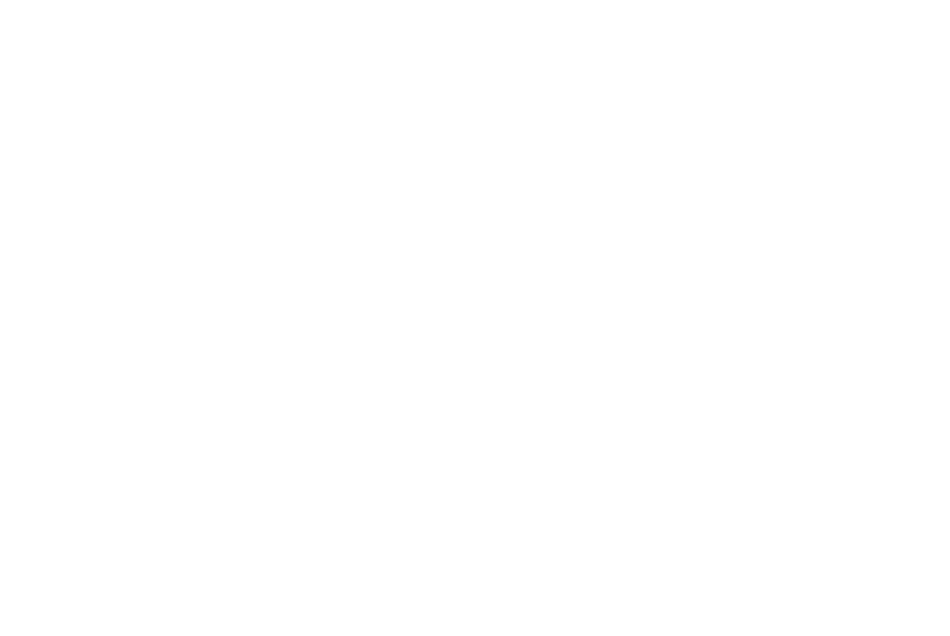

In [22]:
# Some example images
paths = landmarks_df["image_path"]
labels = landmarks_df["letter"]


np_random_seed = np.random.default_rng(42)
sample_indices = np_random_seed.choice(
    len(paths),
    size=min(6, len(paths)),
    replace=False,
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:
    ax.axis("off")

with create_landmarker(hand_model_path="../models/hand_landmarker.task") as landmarker:
    for ax, index in zip(axes.flat, sample_indices):
        path = paths[index]
        print(path)

        _, landmarks, rgb = get_features(str(paths[index]), landmarker)

        ax.imshow(rgb)

        if landmarks:
            height, width = rgb.shape[:2]
            ax.scatter(
                [point.x * width for point in landmarks],
                [point.y * height for point in landmarks],
                s=12,
                c="lime",
            )
            status = "detected"
        else:
            status = "NO HAND"

        ax.set_title(f"{labels[index]}: {status}")
        print(f"{LABEL_MAP[labels[index]]}: {status} ({path})")

plt.tight_layout()
plt.show()

In [23]:
landmarker = create_landmarker(hand_model_path="../models/hand_landmarker.task")


MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792617156.938563 7729611 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792617156.943338 7729611 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [24]:
train_ok = ~landmarks_df["no_hand"]
failures = landmarks_df.loc[~train_ok, "image_path"]

print(f"Training hand detection: {train_ok.mean():.2%}")
print("First loading/detection failures:\n", failures[:3].values)

Training hand detection: 80.02%
First loading/detection failures:
 <StringArray>
[     '../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg',
 '../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002_copy.jpg',
      '../data/dataset/D01_megadataset/A/A03_kaggle_asl__1004.jpg']
Length: 3, dtype: str


## Train / Validation / Test Split (once)

In [25]:
# shuffle training data
np_random_seed = np.random.default_rng(42)
train_indexes = np_random_seed.permutation(landmarks_df.query("train & ~no_hand").index.values)
X_train = landmarks_df.loc[train_indexes].iloc[:, 1:64]
y_train = landmarks_df.loc[train_indexes]["letter_index"]
print(X_train.columns)

# Validation
val_indexes = landmarks_df.query("val & ~no_hand").index.values
X_val = landmarks_df.loc[val_indexes].iloc[:, 1:64]
y_val = landmarks_df.loc[val_indexes]["letter_index"]
val_users_indexes = landmarks_df.query("val & ~no_hand & had_user").index.values
X_val_users = landmarks_df.loc[val_users_indexes].iloc[:, 1:64]
y_val_users = landmarks_df.loc[val_users_indexes]["letter_index"]

# Validation
test_indexes = landmarks_df.query("test & ~no_hand").index.values
X_test = landmarks_df.loc[test_indexes].iloc[:, 1:64]
y_test = landmarks_df.loc[test_indexes]["letter_index"]
test_users_indexes = landmarks_df.query("test & ~no_hand  & had_user").index.values
X_test_users = landmarks_df.loc[test_users_indexes].iloc[:, 1:64]
y_test_users = landmarks_df.loc[test_users_indexes]["letter_index"]

len(train_indexes), len(val_indexes), len(test_indexes)

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24',
       '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36',
       '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48',
       '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60',
       '61', '62'],
      dtype='str')


(86836, 11854, 11898)

In [26]:
# All 24 classes must have usable training examples.
missing = set(LABEL_MAP.values()) - set(y_train)

if missing:
    raise ValueError(
        f"No usable training images for: {[
            LABEL_MAP[el] for el in sorted(missing)]}"
    )

In [27]:
y_train.value_counts().sort_index()

letter_index
0     3924
1     5145
2     4774
3     5363
4     2810
5     5695
6     5301
7     5283
8     5494
9     4880
10    5467
11    2490
12    2133
13    3094
14    1879
15    1449
16    2957
17    2231
18    2751
19    2762
20    3712
21    2602
22    2080
23    2560
Name: count, dtype: int64

In [28]:
classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=25,
    n_estimators=400,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.8,
    min_child_weight=3,
    reg_lambda=5,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    #early_stopping_rounds= 80,
    random_state=42,
    n_jobs=4,
)

In [29]:
classifier.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val), (X_val_users, y_val_users)],
)

[0]	validation_0-mlogloss:2.80443	validation_1-mlogloss:2.82932	validation_2-mlogloss:3.09890
[1]	validation_0-mlogloss:2.58909	validation_1-mlogloss:2.62284	validation_2-mlogloss:2.97785
[2]	validation_0-mlogloss:2.41876	validation_1-mlogloss:2.45819	validation_2-mlogloss:2.87316
[3]	validation_0-mlogloss:2.27760	validation_1-mlogloss:2.32206	validation_2-mlogloss:2.78908
[4]	validation_0-mlogloss:2.15406	validation_1-mlogloss:2.20230	validation_2-mlogloss:2.70684
[5]	validation_0-mlogloss:2.04328	validation_1-mlogloss:2.09519	validation_2-mlogloss:2.63114
[6]	validation_0-mlogloss:1.94466	validation_1-mlogloss:1.99977	validation_2-mlogloss:2.56524
[7]	validation_0-mlogloss:1.85845	validation_1-mlogloss:1.91701	validation_2-mlogloss:2.51317
[8]	validation_0-mlogloss:1.77720	validation_1-mlogloss:1.83809	validation_2-mlogloss:2.45431
[9]	validation_0-mlogloss:1.70222	validation_1-mlogloss:1.76578	validation_2-mlogloss:2.40404
[10]	validation_0-mlogloss:1.63414	validation_1-mlogloss:1.6

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

In [30]:
landmarks_df["y_pred"] = -1
landmarks_df.loc[landmarks_df["no_hand"], "y_pred"] = 24
landmarks_df.loc[train_indexes, "y_pred"] = classifier.predict(X_train)
landmarks_df.loc[val_indexes, "y_pred"] = classifier.predict(X_val)
landmarks_df.loc[test_indexes, "y_pred"] = classifier.predict(X_test)

# Train
model_evaluation("train")
print()

# Validation
model_evaluation("val")
print()

# Test
model_evaluation("test", include_reports=True, include_confusion_matrix=True);
print()


AttributeError: 'str' object has no attribute 'loc'


train
Images: 3600
Usable hand detection: 99.89%
Overall accuracy: 98.89%
Accuracy on detected hands: 99.00%


val
Images: 1440
Usable hand detection: 100.00%
Overall accuracy: 80.49%
Accuracy on detected hands: 80.49%


test
Images: 1440
Usable hand detection: 100.00%
Overall accuracy: 80.56%
Accuracy on detected hands: 80.56%

Overall Classification report
              precision    recall  f1-score   support

           A      0.833     1.000     0.909        60
           B      1.000     1.000     1.000        60
           C      0.785     0.850     0.816        60
           D      0.742     0.817     0.778        60
           E      0.500     0.983     0.663        60
           F      1.000     0.950     0.974        60
           G      0.863     0.733     0.793        60
           H      0.979     0.767     0.860        60
           I      0.982     0.900     0.939        60
           K      1.000     0.983     0.992        60
           L      1.000     0.983     0.992

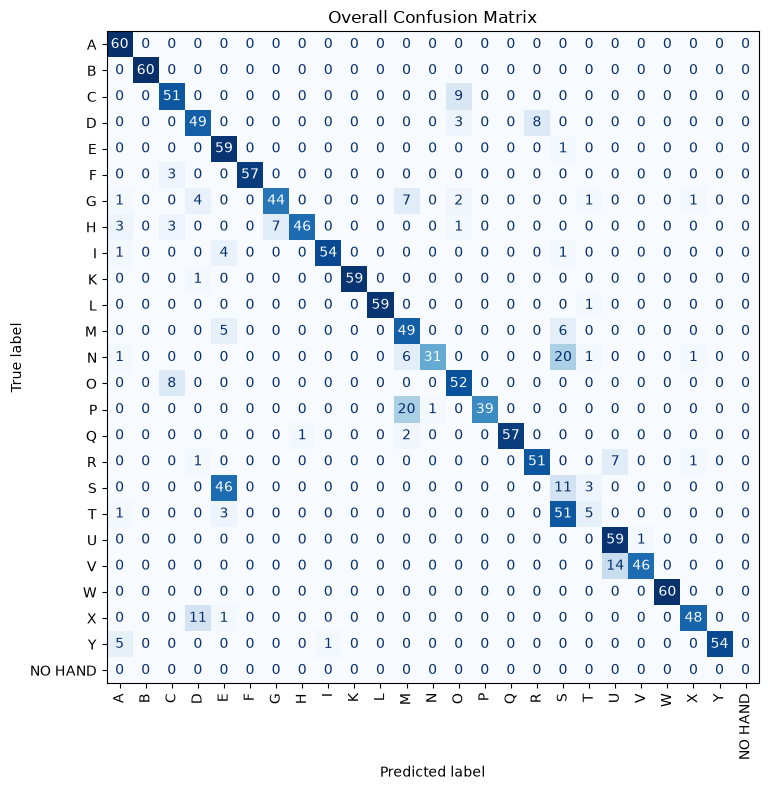

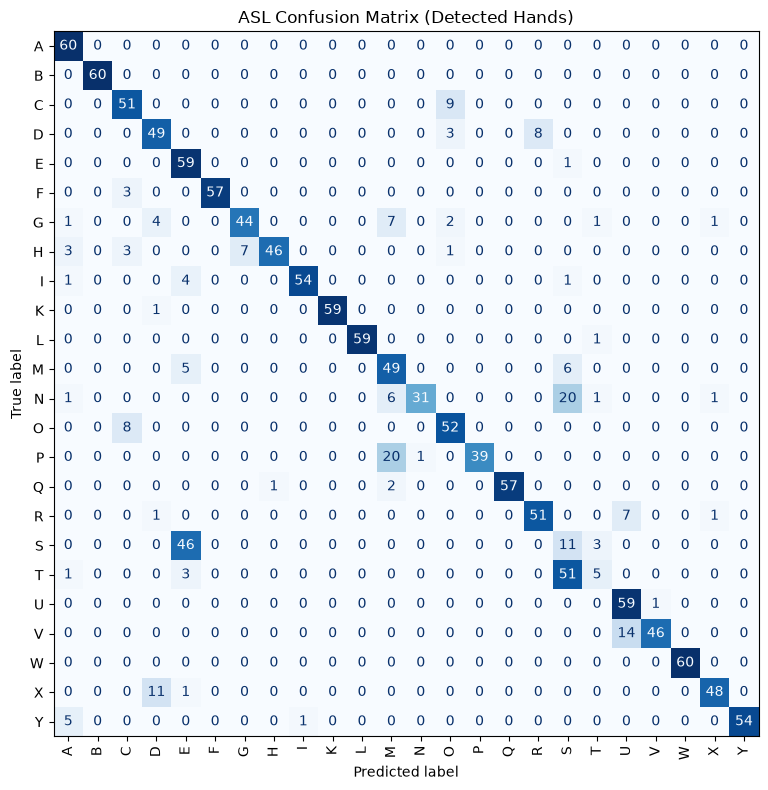

In [ ]:
landmarks_df["y_pred"] = -1
landmarks_df.loc[landmarks_df["no_hand"], "y_pred"] = 24
landmarks_df.loc[train_indexes, "y_pred"] = classifier.predict(X_train)
landmarks_df.loc[val_indexes, "y_pred"] = classifier.predict(X_val)
landmarks_df.loc[test_indexes, "y_pred"] = classifier.predict(X_test)

dataset_had_users = landmarks_df["dataset"].isin(["B01_original_aslmnist", "B02_aslyset"])

# Train
model_evaluation("train", landmarks_df.loc[dataset_had_users])
print()

# Validation
model_evaluation("val", landmarks_df.loc[dataset_had_users])
print()

# Test
overall_confusion, asl_confusion = model_evaluation(
    "test",
    landmarks_df.loc[dataset_had_users],
    include_reports=True,
    include_confusion_matrix=True
);
print()

### Train on all and save model

In [31]:
classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=len(LETTERS),
    n_estimators=400,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.8,
    min_child_weight=3,
    reg_lambda=5,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="merror",
    #early_stopping_rounds= 80,
    random_state=42,
    n_jobs=4,
)
classifier.fit(
    pd.concat([X_train, X_val, X_test]),
    pd.concat([y_train, y_val, y_test]),
)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

In [32]:
import joblib
joblib.dump(classifier, "../models/handspell_xgboost_megadata_dpessoa.joblib")

['../models/handspell_xgboost_megadata_dpessoa.joblib']

## Test on A02 Kaggle Ahmed Khanak Dataset - poor lighting

In [ ]:
# from handspell.model_landmarks_training import extract_features
# # Test on hard dataset

# dataset_path = "../data/raw_data/A02_kaggle_ahmedkhanak/selected_gestures"
# paths, labels = find_images(dataset_path)
# features, failures = extract_features(paths)
# y_pred_hard = classifier.predict(features)

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792536585.823815 6978534 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792536585.829261 6978536 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/36000 [00:00<?, ?it/s]

In [ ]:
# features.shape, y_pred_hard.shape, len(failures), len(paths)

((36000, 63), (36000,), 10312, 36000)

In [ ]:
# np.isnan(features[:,0])

array([False, False, False, ...,  True,  True,  True], shape=(36000,))

In [ ]:
# y_pred_hard[np.isnan(features[:,0])] = -1

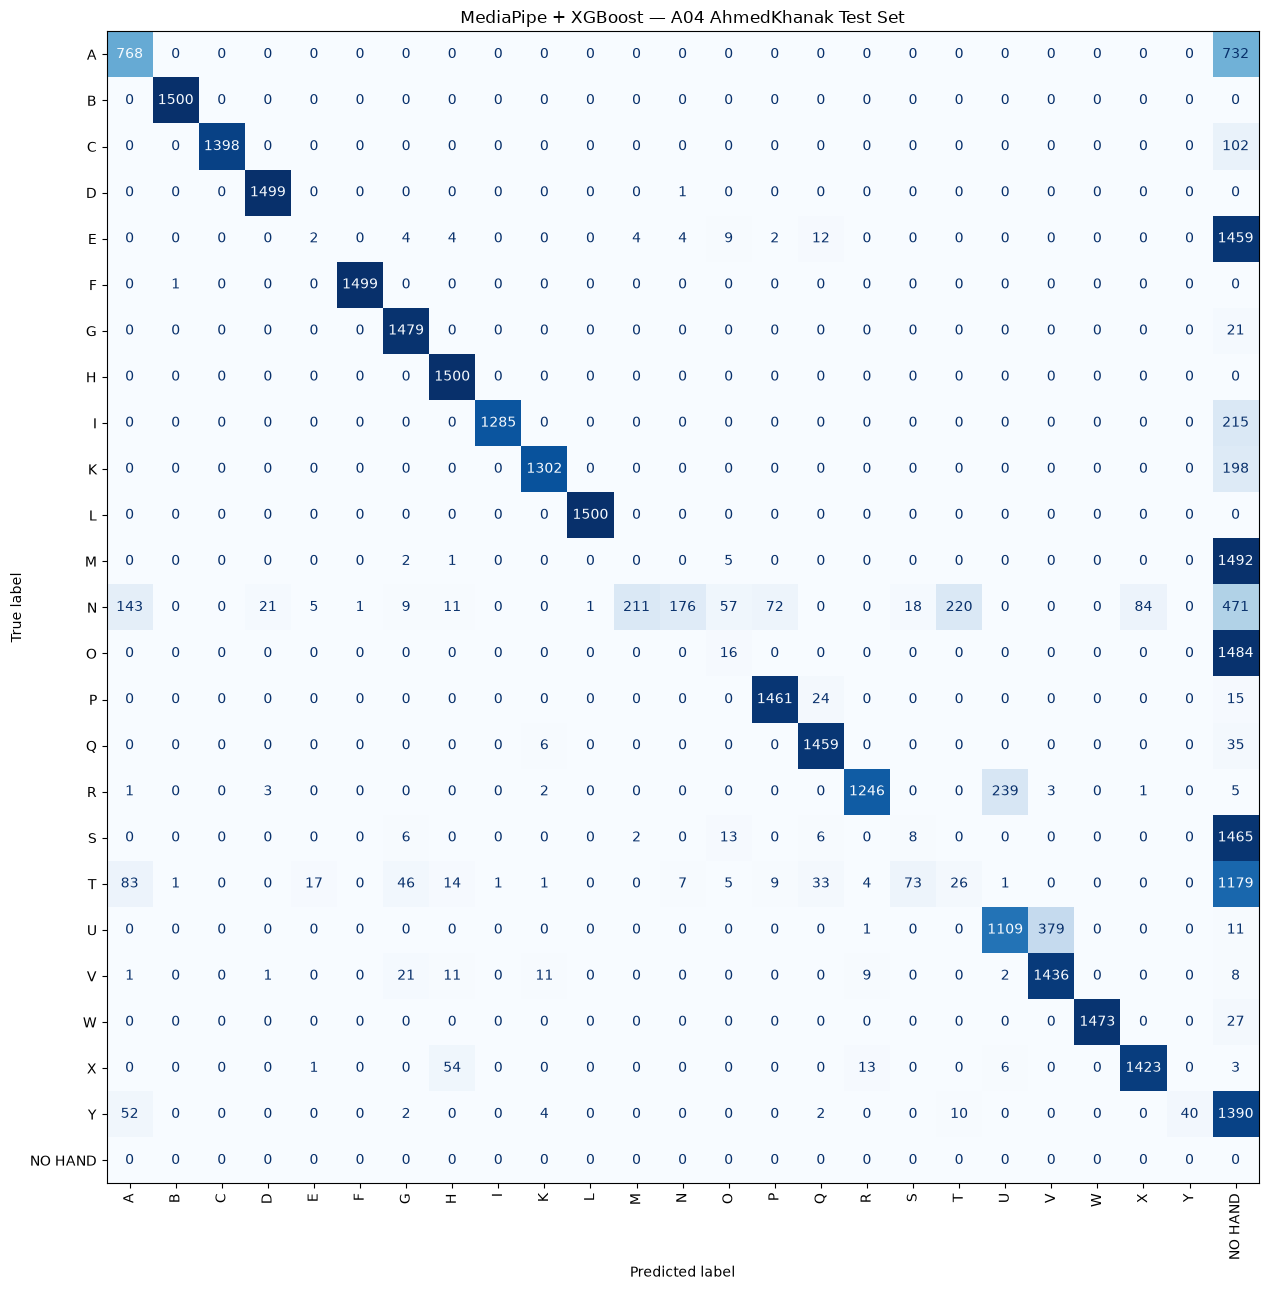

In [ ]:
# from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# true_letters = [LETTERS[i] for i in labels]
# y_pred_hard_nohands = np.array([li if not np.isnan(features[i,0]) else 24 for i, li in enumerate(y_pred_hard)])
# # When no hand, set prediction to "NO HAND"


# matrix = confusion_matrix(
#     labels,
#     y_pred_hard_nohands,
#     #labels=list(LETTERS)+["NO HAND"],
# )

# fig, ax = plt.subplots(figsize=(16, 13))

# ConfusionMatrixDisplay(
#     confusion_matrix=matrix,
#     display_labels=list(LETTERS)+["NO HAND"],
# ).plot(
#     ax=ax,
#     cmap="Blues",
#     values_format="d",
#     xticks_rotation=90,
#     colorbar=False,
# )

# ax.set_title("MediaPipe + XGBoost — A04 AhmedKhanak Test Set")
# plt.tight_layout()
# plt.show()